# Week 9 - Multivariate Analysis, part 2

# 1. Lesson - no lesson this week

# 2. Weekly graph question

The graph below plots the first two principal component scores in a scatter plot.  What can be said about the three outliers in the upper left corner of the graph?  Is their first principal component score high or low?  What about their second principal component score?  What does that mean about their values in series_1, series_2, and series_3?  It seems to me that you can say something about series_3 (what can you say?) but you may have a harder time saying something about series_1 and series_2, and an almost impossible time saying anything about the relative values of series_1 and series_2.  Why is that?  How are series_1 and series_2 related, according to how they were created?  If you like, try drawing a pairplot for all three series and see what you get.

Overall, what are the advantages and disadvantages of the graph below?  Does it show anything interesting?

[0.79916477 0.18990532 0.01092991]
[[ 0.26541493  0.30096233  0.91595665]
 [ 0.60337553  0.6891417  -0.40127506]
 [ 0.75199261 -0.65917023 -0.00131519]]


Text(0, 0.5, 'Second Principal Component Score')

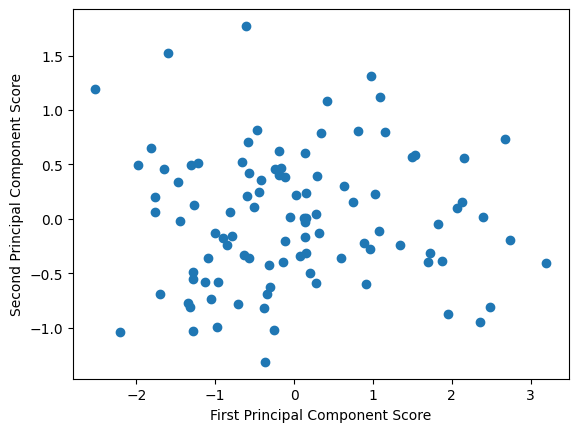

In [1]:
import numpy as np
import pandas as pd
from fontTools.pens.wxPen import WxPen
from sklearn import decomposition
import matplotlib.pyplot as plt

np.random.seed(0)
num_points = 100
series_1 = np.random.normal(loc = 2, scale = 0.5, size = num_points)
series_2 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.1, size = num_points))
series_3 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.5, size = num_points))
df = pd.DataFrame({'ser1': series_1, 'ser2': series_2, 'ser3': series_3})
df = df - df.mean() # set mean to zero, so we don't have to subtract mean from the principal component scores

pca3 = decomposition.PCA(n_components = 3)
pca3.fit(df)
print(pca3.explained_variance_ratio_)
print(pca3.components_)

first_principal_component_score = df.dot(pca3.components_[0])
second_principal_component_score = df.dot(pca3.components_[1])
plt.scatter(first_principal_component_score, second_principal_component_score)
plt.xlabel("First Principal Component Score")
plt.ylabel("Second Principal Component Score")

In [ ]:
"""
1) The 3 outliers have a low first principal component score and then have a high principal component score
2) The outliers for series 3 have low values as compared to series 1 and series 2.  
3) Series 3 has very large weight in the first principal component (0.916), which causes it to strongly influence the horizontal position. Series 1 and 2 have similiar weights in the principal components, which makes it challenging to differentiate from each other.
4) Series 2 was created from series 1 with a small amount of variation. Therefore, series 1 and 2 are strongly positively related.
5) A pairplot would show a very strong positive relationship between series 1 and 2. Series 3 would be more spread out because it contains more random variation.
6) The PCA graph reduces three variables to two dimensions, making patterns and outliers easier to see.
7) The principal components are combinations of the original variables, so the graph is more challenging to interpret than graphs showing each of series directly.
8) Yes, the graph clearly shows 3 outliers in the upper left corner, which show low series 3 values as compared to series 1 and 2.
"""

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:
Draw heatmaps.

Draw bubble plots.

Perform Principal Component Analysis to find out the directions in which the data varies.  Can you represent the data using only its projection onto its first principal component, using the methods described in Week 8?  How much of the variance would this capture?

Try performing linear regression analysis using different sets of features.  Which features seem most likely to be useful to predict other features?

Conclusions:
Explain what conclusions you would draw from this analysis: are the data what you expect? Are the data likely to be usable? If the data are not useable, find some new data!

Do you see any outliers? (Data points that are far from the rest of the data).

Does the Principal Component Analysis suggest a way to represent the data using fewer dimensions than usual - using its first one or two principal component scores, perhaps?

Try using your correlation information from previous weeks to help choose features for linear regression.

BRFSS Analysis

In [4]:
import pandas as pd
#BRFSS Dataset

#Load BRFSS Data
brfss_path = r"C:\Users\dmerce1\OneDrive - UHG\BU MS Data Science\DX699 - AI for Leader pt. 2\AI_Leaders\BRFSS.csv"

df_brfss = pd.read_csv(brfss_path)
print(df_brfss.shape)

(337894, 301)


In [5]:
#BRFSS Variables for Multivariate Analysis

brfss_multi = df_brfss[[
    'DIABETE4',   #Diabetes
    'CVDINFR4',   #Heart Attack
    'CVDCRHD4',   #Heart Disease
    'CVDSTRK3',   #Stroke
    'CHCCOPD3',   #COPD
    'CHCKDNY2',   #Kidney Disease
    '_AGEG5YR',   #Age Group
    '_INCOMG1',   #Income Group
    'GENHLTH',    #General Health
]]. copy()

print(brfss_multi.shape)

brfss_multi.head()

(337894, 9)


,DIABETE4,CVDINFR4,CVDCRHD4,CVDSTRK3,CHCCOPD3,CHCKDNY2,_AGEG5YR,_INCOMG1,GENHLTH
0,3,2,2,2,2,2,12.0,9.0,3
1,3,2,1,2,2,2,13.0,7.0,1
2,3,2,2,2,2,2,8.0,9.0,2
3,3,2,2,2,2,2,13.0,4.0,1
4,3,2,2,2,2,2,6.0,2.0,3


In [6]:
brfss_multi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337894 entries, 0 to 337893
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   DIABETE4  337894 non-null  int64  
 1   CVDINFR4  337894 non-null  int64  
 2   CVDCRHD4  337894 non-null  int64  
 3   CVDSTRK3  337894 non-null  int64  
 4   CHCCOPD3  337894 non-null  int64  
 5   CHCKDNY2  337894 non-null  int64  
 6   _AGEG5YR  337893 non-null  float64
 7   _INCOMG1  337893 non-null  float64
 8   GENHLTH   337894 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 23.2 MB


In [7]:
brfss_multi.isnull().sum()

DIABETE4    0
CVDINFR4    0
CVDCRHD4    0
CVDSTRK3    0
CHCCOPD3    0
CHCKDNY2    0
_AGEG5YR    1
_INCOMG1    1
GENHLTH     0
dtype: int64

In [8]:
#Clean BRFSS Variables

brfss_pca = brfss_multi.copy()


#Recode Chronic Disease Variables
binary_disease_cols = [
    'CVDINFR4',   #Heart Attack
    'CVDCRHD4',   #Heart Disease
    'CVDSTRK3',   #Stroke
    'CHCCOPD3',   #COPD
    'CHCKDNY2'    #Kidney Disease
]

for col in binary_disease_cols:
    brfss_pca[col] = brfss_pca[col].map({
        1: 1,  #Yes
        2: 0,  #No
    })

#Recode Diabetes
brfss_pca['DIABETE4'] = brfss_pca['DIABETE4'].map({
    1: 1,  #Diabetes
    2: 0,  #Pregnancy Only
    3: 0,  #No
    4: 0   #Prediabetes/borderline
})

#General Health
brfss_pca['GENHLTH'] = brfss_pca['GENHLTH'].where(
    brfss_pca['GENHLTH'].isin([1,2,3,4,5])
)

#Age Groups
brfss_pca['_AGEG5YR'] = brfss_pca['_AGEG5YR'].where(
    brfss_pca['_AGEG5YR'].between(1, 13)
)

#Income Codes
brfss_pca['_INCOMG1'] = brfss_pca['_INCOMG1'].where(
    brfss_pca['_INCOMG1'].between(1, 7)
)

#Missing values
print("\nMissing Values:")
print(brfss_pca.isnull().sum())

#Remove Records with Missing Values
brfss_pca_clean = brfss_pca.dropna().copy()

#Compare dataset
print("\nOriginal Dataset Shape:")
print(brfss_pca.shape)

print("\nClean Dataset Shape:")
print(brfss_pca_clean.shape)

display(brfss_pca_clean.head())


Missing Values:
DIABETE4      771
CVDINFR4     2325
CVDCRHD4     3394
CVDSTRK3     1080
CHCCOPD3     1609
CHCKDNY2     1487
_AGEG5YR     6297
_INCOMG1    64071
GENHLTH       991
dtype: int64

Original Dataset Shape:
(337894, 9)

Clean Dataset Shape:
(265196, 9)


,DIABETE4,CVDINFR4,CVDCRHD4,CVDSTRK3,CHCCOPD3,CHCKDNY2,_AGEG5YR,_INCOMG1,GENHLTH
1,0.0,0.0,1.0,0.0,0.0,0.0,13.0,7.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0,13.0,4.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2.0,3.0
5,1.0,0.0,0.0,0.0,0.0,0.0,7.0,6.0,3.0
6,0.0,1.0,0.0,0.0,0.0,0.0,11.0,4.0,4.0


In [10]:
#Standardize BRFSS Variables for PCA
from sklearn.preprocessing import StandardScaler
pca_features = [
    'DIABETE4',   #Diabetes
    'CVDINFR4',   #Heart Attack
    'CVDCRHD4',   #Heart Disease
    'CVDSTRK3',   #Stroke
    'CHCCOPD3',   #COPD
    'CHCKDNY2',   #Kidney Disease
    '_AGEG5YR',   #Age Group
    '_INCOMG1',   #Income Group
    'GENHLTH',    #General Health
]

#PCA Variables
X = brfss_pca_clean[pca_features]

#Standarize Variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original PCA Dataset Shape:")
print(X.shape)

print("\nStandardized Dataset Shape:")
print(X_scaled.shape)

Original PCA Dataset Shape:
(265196, 9)

Standardized Dataset Shape:
(265196, 9)


In [11]:
#Create PCA
from sklearn.decomposition import PCA   
pca =PCA()
X_pca = pca.fit_transform(X_scaled)

#Variance

explained_variance = pca.explained_variance_ratio_

print("Explained Variance by Principal Component:")

for i, variance in enumerate(explained_variance, start=1):
    print(f"PC{i}: {variance:.2%}")

#Cumulative Explained Variance

cumulative_variance = np.cumsum(explained_variance)

print("\nCumulative Explained Variance:")

for i, variance in enumerate(cumulative_variance, start=1):
    print(f"PC1 through PC{i}: {variance:.2%}")

Explained Variance by Principal Component:
PC1: 25.96%
PC2: 12.78%
PC3: 11.11%
PC4: 9.93%
PC5: 9.68%
PC6: 9.36%
PC7: 8.29%
PC8: 6.94%
PC9: 5.95%

Cumulative Explained Variance:
PC1 through PC1: 25.96%
PC1 through PC2: 38.74%
PC1 through PC3: 49.85%
PC1 through PC4: 59.78%
PC1 through PC5: 69.46%
PC1 through PC6: 78.82%
PC1 through PC7: 87.11%
PC1 through PC8: 94.05%
PC1 through PC9: 100.00%


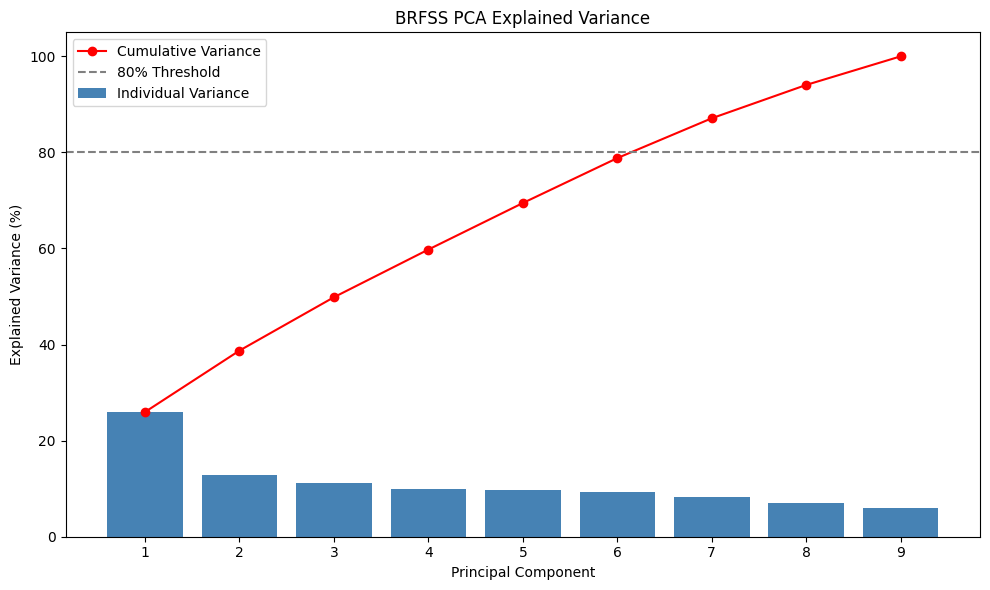

In [12]:
#Visualize PCA

components = range(1, len(explained_variance) + 1)

plt.figure(figsize=(10, 6))

plt.bar(
    components,
    explained_variance * 100,
    color='steelblue',
    label='Individual Variance'
)

plt.plot(
    components,
    cumulative_variance * 100,
    color = 'red',
    marker = 'o',
    label = 'Cumulative Variance'
)

plt.axhline(
    y=80,
    color = 'gray',
    linestyle = '--',
    label = '80% Threshold'
)

plt.title('BRFSS PCA Explained Variance')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')

plt.xticks(components)
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
#PCA Loadings

loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[f'PC{i}' for i in range(1, len(pca_features)+ 1)]
)

loadings_display = (
    loadings
    .reset_index()
    .rename(columns={'index': 'Variable'})
)
display(loadings_display.round(3))

,Variable,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
0,DIABETE4,0.328,-0.113,0.499,-0.016,-0.103,-0.563,0.405,-0.368,0.052
1,CVDINFR4,0.388,0.448,-0.308,-0.157,-0.186,-0.075,-0.039,-0.176,-0.675
2,CVDCRHD4,0.397,0.458,-0.215,-0.263,-0.109,-0.026,-0.020,0.080,0.705
3,CVDSTRK3,0.277,0.075,-0.142,0.906,-0.132,0.163,0.152,-0.041,0.084
4,CHCCOPD3,0.312,-0.231,-0.247,-0.155,0.663,0.333,0.394,-0.242,-0.005
5,CHCKDNY2,0.273,-0.039,0.535,-0.156,-0.318,0.703,-0.084,-0.097,-0.037
6,_AGEG5YR,0.319,0.187,0.391,0.165,0.570,-0.151,-0.524,0.233,-0.079
7,_INCOMG1,-0.276,0.559,0.286,0.017,0.167,0.115,0.581,0.372,-0.111
8,GENHLTH,0.397,-0.409,-0.085,-0.096,-0.177,-0.093,0.191,0.752,-0.130


In [ ]:
#BRFSS Analysis
"""
PCA Summary:
PCA was used to determine whether the nine BRFSS variables could be summarized with fewer components. PC1 explained 25.96% of the variance. PC1 and PC2 explained 38.74%. Roughly 79% required six components. The loadings show that PC1 was influenced by multiple variables rather than one main variable. The largest contributors are Heart Disease, General Health, Heart Attack, Diabetes, Age, and COPD.
"""

In [14]:
#Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

#Outcome Variable
y= brfss_pca_clean['GENHLTH']

#Feature Set

feature_sets = {
    'Model 1 - Age and Income': [
        '_AGEG5YR',
        '_INCOMG1'
    ],
    'Model 2 - Chronic Diseases': [
    'DIABETE4',   #Diabetes
    'CVDINFR4',   #Heart Attack
    'CVDCRHD4',   #Heart Disease
    'CVDSTRK3',   #Stroke
    'CHCCOPD3',   #COPD
    'CHCKDNY2',   #Kidney Disease
    ],
    'Model 3 - Age, Income, and Chronic Diseases': [
        '_AGEG5YR',
        '_INCOMG1',
        'DIABETE4',   #Diabetes
        'CVDINFR4',   #Heart Attack
        'CVDCRHD4',   #Heart Disease
        'CVDSTRK3',   #Stroke
        'CHCCOPD3',   #COPD
        'CHCKDNY2',   #Kidney Disease
    ]}

results =[]
#Run Models
for model_name, features in feature_sets.items():
    X = brfss_pca_clean[features]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    
    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    
    results.append({
        'Model': model_name,
        'R-Squared': r2,
        'RMSE': rmse})
    
#Display
results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,R-Squared,RMSE
0,Model 1 - Age and Income,0.112,0.980
1,Model 2 - Chronic Diseases,0.154,0.957
2,"Model 3 - Age, Income, and Chronic Diseases",0.208,0.926


In [ ]:
#BRFSS Linear Regression Summary
"""
Summary:
Three linear regression models were compared to determine which variables were most useful for explaining general health: Age, Income, and chronic disease indicators were selected because earlier exploratory and correlation analysis identified relationships among these characteristics and health outcomes, while also aligning with the chronic disease focus of the capstone project.
- Age and Income: r2 = 0.112, RMSE = 0.980
- Chronic Diseases: r2 = 0.154, RMSE = 0.957
- Age and Income and Chronic Diseases: r2 = 0.208, RMSE = 0.926

Conclusion:
The combined model performed the best because it had the highest r2 and lowest RMSE. Age, Income, and Chronic Disease variables together explained that approximately 20.8% of the variation in General Health. This suggests that demographics and chronic disease characteristics provide more useful information when considered together than when analyzed separately. However, most of the variation in General Health is still unexplained, which suggests that other factors also influence respondents health ratings.
"""

In [15]:
#Outliers using PC1 and PC2

pca_scores = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1]
})

#Calc z-scores for PC1 and PC2
pca_scores['PC1_Z'] = ((pca_scores['PC1'] - pca_scores['PC1'].mean()) / pca_scores['PC1'].std())
pca_scores['PC2_Z'] = ((pca_scores['PC2'] - pca_scores['PC2'].mean()) / pca_scores['PC2'].std())

#Identify Observations
outliers = pca_scores[(pca_scores['PC1_Z'].abs() > 3) | (pca_scores['PC2_Z'].abs() > 3)]

print("Total Records:", len(pca_scores))
print("Potential Outliers:", len(outliers))
print("Percent of Records:", round(len(outliers) / len(pca_scores) * 100, 2), "%")

Total Records: 265196
Potential Outliers: 8386
Percent of Records: 3.16 %


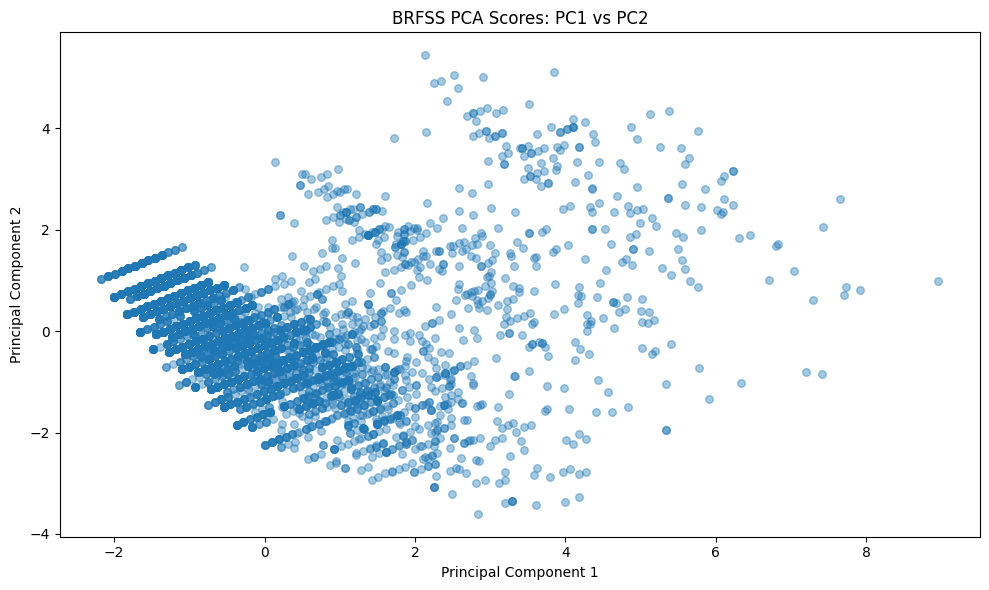

In [16]:
#Outlier Visualization

import matplotlib.pyplot as plt

#Sample
plot_df = pca_scores.sample(n=5000, random_state=42)

plt.figure(figsize=(10,6))
plt.scatter(
    plot_df['PC1'],
    plot_df['PC2'],
    alpha=0.4,
    s=30)

plt.title('BRFSS PCA Scores: PC1 vs PC2')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

In [ ]:
#Outlier Conclusion
"""
The PCA outlier analysis identified 8,386 potential outliers, representing 3.16% of the BRFSS records analyzed. The PC1 versus PC2 scatterplot shows that most observations are grouped together, with a small number located farther from the main cluster. Since PC1 and PC2 explain only 38.74% of the total variation, these records may appear unusual based on the first two principal components but may not be unusual when all nine variables are considered.
"""

In [ ]:
#BRFSS Analysis Conclusion
"""Conclusion:
The PCA results show that the BRFSS variables contain several different types of information. The first two components explained only 38.74% of the total variance, so reducing the dataset to only one or two components would result in significant information loss. Six components captured 78.82% of the variance, while seven captured 87.11%, suggesting that several components are needed to adequately represent the chronic disease, demographic, and health information in the dataset.

The linear regression results showed that the model combining age, income, and chronic disease indicators performed best with an r2 of 0.208 and RMSE of 0.926. This suggests that demographic and chronic disease characteristics provide more information about General Health when considered together, although much of the variation in General Health is still unexplained.

The outlier analysis identified 8,386 potential outliers, representing 3.16% of the 265,196 records analyzed. Since this is a small portion of the dataset, the potential outliers do not appear to significantly affect the overall results. The cleaned BRFSS dataset remains usable for multivariate analysis and provides a large sample for PCA, regression, and outlier analysis. Overall, the results were consistent with expectations because chronic diseases, age, income, and general health represent different characteristics and would not necessarily be expected to be summarized effectively by only one or two principal components.
"""

NHANES Analysis

In [17]:
#Load NHANES Dataset

import pandas as pd
nhanes_path = r"C:\Users\dmerce1\OneDrive - UHG\BU MS Data Science\DX699 - AI for Leader pt. 2\AI_Leaders\DEMO_L.csv"

df_nhanes = pd.read_csv(nhanes_path)
print("NHANES Dataset Shape:")
print(df_nhanes.shape)

display(df_nhanes.head())

NHANES Dataset Shape:
(11933, 27)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378,12,2,1,43,NaN,5,6,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.45081,54374.46390,173,2,5.00
1,130379,12,2,1,66,NaN,3,3,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.45061,34084.72155,173,2,5.00
2,130380,12,2,2,44,NaN,2,2,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.67430,81196.27799,174,1,1.41
3,130381,12,2,2,5,NaN,5,7,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.26890,55698.60711,182,2,1.53
4,130382,12,2,1,2,NaN,3,3,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.51977,36434.14635,182,2,3.60


In [18]:
#Review NHANES Fields

print("NHANES Columns")
for col in df_nhanes.columns:
  print(col)

print("\nData Types:")
print(df_nhanes.dtypes)

print("\nmMissing Values:")
print(df_nhanes.isnull().sum().sort_values(ascending=False))

NHANES Columns
SEQN
SDDSRVYR
RIDSTATR
RIAGENDR
RIDAGEYR
RIDAGEMN
RIDRETH1
RIDRETH3
RIDEXMON
RIDEXAGM
DMQMILIZ
DMDBORN4
DMDYRUSR
DMDEDUC2
DMDMARTZ
RIDEXPRG
DMDHHSIZ
DMDHRGND
DMDHRAGZ
DMDHREDZ
DMDHRMAZ
DMDHSEDZ
WTINT2YR
WTMEC2YR
SDMVSTRA
SDMVPSU
INDFMPIR

Data Types:
SEQN          int64
SDDSRVYR      int64
RIDSTATR      int64
RIAGENDR      int64
RIDAGEYR      int64
RIDAGEMN    float64
RIDRETH1      int64
RIDRETH3      int64
RIDEXMON    float64
RIDEXAGM    float64
DMQMILIZ    float64
DMDBORN4    float64
DMDYRUSR    float64
DMDEDUC2    float64
DMDMARTZ    float64
RIDEXPRG    float64
DMDHHSIZ      int64
DMDHRGND    float64
DMDHRAGZ    float64
DMDHREDZ    float64
DMDHRMAZ    float64
DMDHSEDZ    float64
WTINT2YR    float64
WTMEC2YR    float64
SDMVSTRA      int64
SDMVPSU       int64
INDFMPIR    float64
dtype: object

mMissing Values:
RIDAGEMN    11556
RIDEXPRG    10430
DMDYRUSR    10058
DMDHSEDZ     9806
RIDEXAGM     9146
DMDHREDZ     8187
DMDHRMAZ     7913
DMDHRGND     7818
DMDHRAGZ     7809


In [19]:
# Select NHANES Variables for PCA

nhanes_pca = df_nhanes[[
    'RIDAGEYR',  #Age
    'INDFMPIR',  #Income to Poverty Ratio
    'DMDHHSIZ',  #Household Size
    'DMDEDUC2'   #Education Level
]
].copy()

print("Original PCA Dataset Shape:")
print(nhanes_pca.shape)

print("\nMissing Values:")
print(nhanes_pca.isnull().sum())

display(nhanes_pca.head())

Original PCA Dataset Shape:
(11933, 4)

Missing Values:
RIDAGEYR       0
INDFMPIR    2041
DMDHHSIZ       0
DMDEDUC2    4139
dtype: int64


,RIDAGEYR,INDFMPIR,DMDHHSIZ,DMDEDUC2
0,43,5.00,4,5.0
1,66,5.00,2,5.0
2,44,1.41,7,3.0
3,5,1.53,2,NaN
4,2,3.60,4,NaN


In [20]:
#Review NHANES Education and Household Size Values

print("Education Values:")
print(nhanes_pca['DMDEDUC2'].value_counts(dropna=False).sort_index())

print("\nHousehold Size Values:")
print(nhanes_pca['DMDHHSIZ'].value_counts(dropna=False).sort_index())

print("\nIncome-to-Poverty Ratio:")
print(nhanes_pca['INDFMPIR'].describe())

Education Values:
DMDEDUC2
1.0     373
2.0     666
3.0    1749
4.0    2370
5.0    2625
9.0      11
NaN    4139
Name: count, dtype: int64

Household Size Values:
DMDHHSIZ
1    1916
2    3056
3    1912
4    2284
5    1418
6     723
7     624
Name: count, dtype: int64

Income-to-Poverty Ratio:
count    9892.000000
mean        2.708174
std         1.670119
min         0.000000
25%         1.180000
50%         2.500000
75%         4.500000
max         5.000000
Name: INDFMPIR, dtype: float64


In [21]:
#Clean Variables for PCA

nhanes_pca_clean = nhanes_pca.copy()

#Education (Categories 1-5)
nhanes_pca_clean['DMDEDUC2']=nhanes_pca_clean['DMDEDUC2'].where(nhanes_pca_clean['DMDEDUC2'].between(1,5))

#Income to Poverty Ratio
nhanes_pca_clean['INDFMPIR']=nhanes_pca_clean['INDFMPIR'].where(nhanes_pca_clean['INDFMPIR'].between(0,5))

#Household Size Values
nhanes_pca_clean['DMDHHSIZ']=nhanes_pca_clean['DMDHHSIZ'].where(nhanes_pca_clean['DMDHHSIZ'].between(1,7))

#Remove missing selected PCA variable
nhanes_pca_clean = nhanes_pca_clean.dropna().copy()

print("Original Dataset Shape:")
print(nhanes_pca.shape)

print("\nClean PCA Dataset Shape:")
print(nhanes_pca_clean.shape)

print("\nMissing values:")
print(nhanes_pca_clean.isnull().sum())

Original Dataset Shape:
(11933, 4)

Clean PCA Dataset Shape:
(6481, 4)

Missing values:
RIDAGEYR    0
INDFMPIR    0
DMDHHSIZ    0
DMDEDUC2    0
dtype: int64


In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

#PCA Variables
pca_features_nhanes = [
    'RIDAGEYR',  #Age
    'INDFMPIR',  #Income to Poverty Ratio
    'DMDHHSIZ',  #Household Size
    'DMDEDUC2'   #Education Level
]

X_nhanes = nhanes_pca_clean[pca_features_nhanes]

#Standardize Variables
scaler_nhanes = StandardScaler()
X_nhanes_scaled = scaler_nhanes.fit_transform(X_nhanes)

#Perform PCA
pca_nhanes = PCA()
X_nhanes_pca = pca_nhanes.fit_transform(X_nhanes_scaled)

#Variance Explained
explained_variance_nhanes = pca_nhanes.explained_variance_ratio_

print("Explained Variance by Principal Component:")

for i, variance in enumerate(explained_variance_nhanes, start=1):
    print(f"PC{i}: {variance:.2%}")

#Cumulative Variance
cumulative_variance_nhanes = np.cumsum(explained_variance_nhanes)

print("\nCumulative Explained Variance:")
for i, variance in enumerate(cumulative_variance_nhanes, start=1):
    print(f"PC1 through PC{i}: {variance:.2%}")

Explained Variance by Principal Component:
PC1: 39.11%
PC2: 31.83%
PC3: 17.24%
PC4: 11.82%

Cumulative Explained Variance:
PC1 through PC1: 39.11%
PC1 through PC2: 70.94%
PC1 through PC3: 88.18%
PC1 through PC4: 100.00%


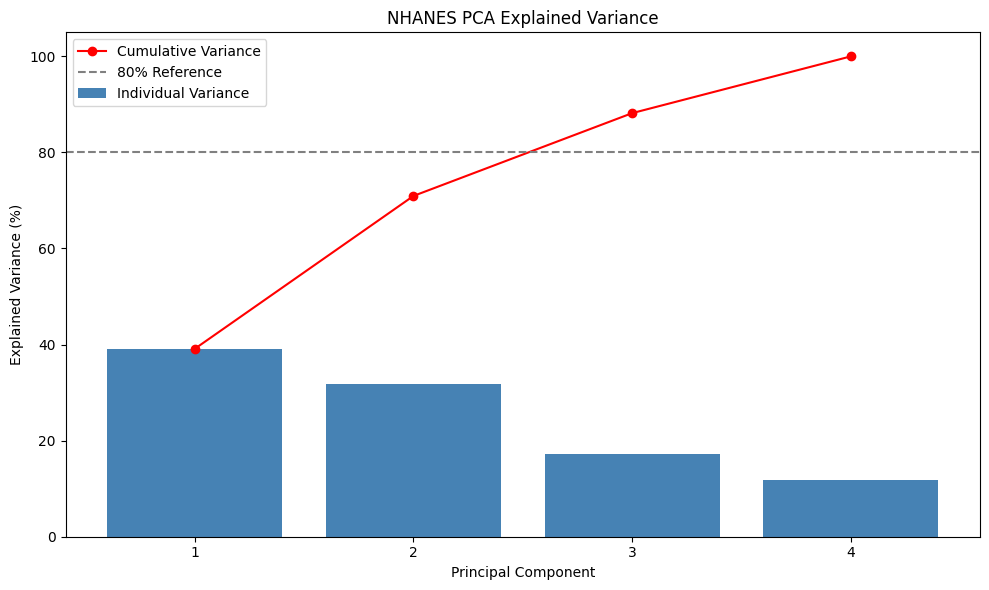

In [31]:
#NHANES PCA Explained Variance Plot

components = range(
    1,
    len(explained_variance_nhanes)+1)

plt.figure(figsize=(10,6))

plt.bar(
    components, 
    explained_variance_nhanes*100,
    color='steelblue',
    label='Individual Variance')

plt.plot(
    components, 
    cumulative_variance_nhanes*100,
    color='red',
    marker='o',
    label='Cumulative Variance')

plt.axhline(
    y=80,
    color='gray',
    linestyle='--',
    label='80% Reference')

plt.title('NHANES PCA Explained Variance')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')

plt.xticks(components)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#PCA Conclusion
"""
The NHANES PCA showed that the first principal component explained 39.11% of the total variance, while the first two components together explained 70.94%. This suggests that the two principal components capture a significant amount of information contained in the four selected variables. Using three components would keep 88.18% of the total variance and provide a more complete representation of the original data.
"""

In [23]:
#NHANES Loadings

loadings_nhanes = pd.DataFrame(
    pca_nhanes.components_.T,
    index=pca_features_nhanes,
    columns=['PC1','PC2', 'PC3', 'PC4']
)

loadings_nhanes_display = (
    loadings_nhanes
    .reset_index()
    .rename(columns={'index': 'Variable'})
)

display(loadings_nhanes_display.round(3))

,Variable,PC1,PC2,PC3,PC4
0,RIDAGEYR,0.182,0.713,0.623,0.266
1,INDFMPIR,0.660,-0.194,0.310,-0.656
2,DMDHHSIZ,-0.366,-0.581,0.713,0.141
3,DMDEDUC2,0.630,-0.340,-0.090,0.693


In [ ]:
#NHANES PCA Loadings

"""
The PCA loadings show that PC1 is driven mostly by Income-to-Poverty Ratio and education, suggesting that the first component reflects socioeconomic characteristics. PC2 is driven primarily by age and household size. Since PC1 and PC2 together explain 70.94% of the total variance, the two components capture  large amount of the information contained in the four selected NHANES variables.
"""

In [30]:
#NHANES Linear Regression Analysis
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

#Outcome Variable
y= nhanes_pca_clean['INDFMPIR']

#Feature Sets
feature_sets = {
    'Model 1 - Age':['RIDAGEYR'],
    'Model 2 - Education and Household Size': ['DMDEDUC2','DMDHHSIZ'],
    'Model 3 - Age, Education, and Household Size': ['RIDAGEYR','DMDEDUC2','DMDHHSIZ']}

#Results
results=[]

#Run Models
for model_name, features in feature_sets.items():
    X =nhanes_pca_clean[features]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42 )
    
    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    results.append({
        'Model': model_name,
        'R-Squared': r2,
        'RMSE': rmse
    })

#Model Comparison
results_df = pd.DataFrame(results)
display(results_df.round(3))


,Model,R-Squared,RMSE
0,Model 1 - Age,0.003,1.642
1,Model 2 - Education and Household Size,0.269,1.406
2,"Model 3 - Age, Education, and Household Size",0.275,1.400


In [ ]:
#Linear Regression Conclusion

"""
The regression analysis shows that Education and Household Size are most useful for explaining income-to-poverty ratio than age. The combined model performed best with an r2 of 0.275 and RMSE of 1.400, but adding Age provided only a small improvement over Education and Household Size alone. This suggests that socioeconomic characteristics are more informative than Age for explaining differences in Income-to-Poverty Ration within the analyzed NHANES population.
"""

In [32]:
#NHANES Outlier Analysis

pca_scores_nhanes = pd.DataFrame({
    'PC1': X_nhanes_pca[:, 0],
    'PC2': X_nhanes_pca[:, 1]
})

#Calc z-scores 
pca_scores_nhanes['PC1_Z'] = ((pca_scores_nhanes['PC1'] - pca_scores_nhanes['PC1'].mean()) / pca_scores_nhanes['PC1'].std())
pca_scores_nhanes['PC2_Z'] = ((pca_scores_nhanes['PC2'] - pca_scores_nhanes['PC2'].mean()) / pca_scores_nhanes['PC2'].std())

#Identify Observations
outliers_nhanes = pca_scores_nhanes[(pca_scores_nhanes['PC1_Z'].abs() > 3) | (pca_scores_nhanes['PC2_Z'].abs() > 3)]

print("Total Records:", len(pca_scores_nhanes))
print("Potential Outliers:", len(outliers_nhanes))
print("Percent of Records:", round(len(outliers_nhanes) / len(pca_scores_nhanes) * 100, 2), "%")

Total Records: 6481
Potential Outliers: 7
Percent of Records: 0.11 %


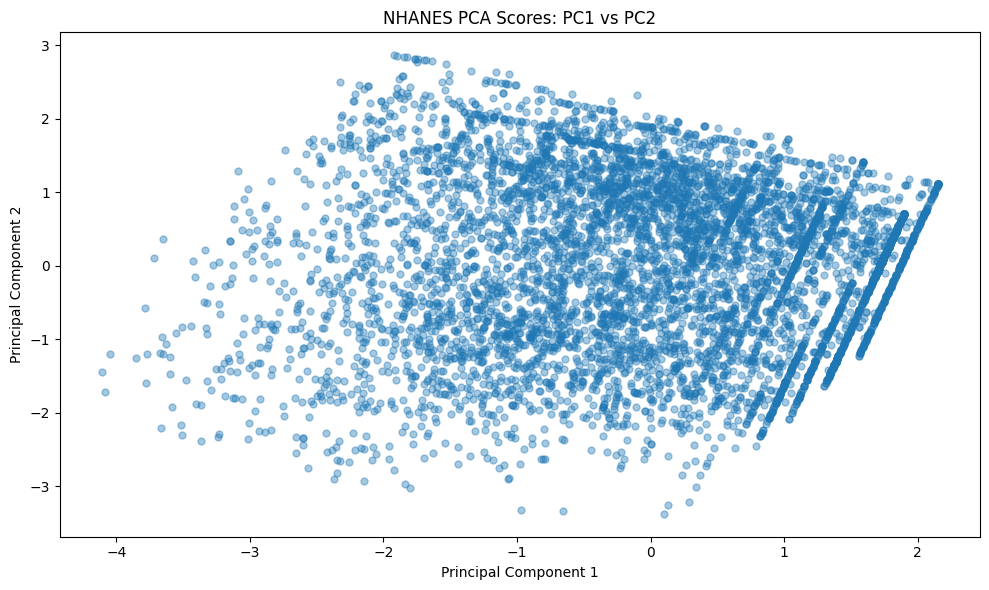

In [33]:
#NHANES Outliers Visual

plt.figure(figsize=(10,6))
plt.scatter(
    pca_scores_nhanes['PC1'],
    pca_scores_nhanes['PC2'],
    alpha=0.4,
    s=25)

plt.title('NHANES PCA Scores: PC1 vs PC2')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

In [ ]:
#Outlier Conclusion

"""
The PCA outlier analysis shows only 7 potential outliers, representing 0.11% of the 6,481 NHANES records analyzed. The PC1 versusPC2 scatterplot shows that most observations follow a similar pattern, with very few observations located far from the main group. Since PC1 and PC2 explain 70.94% of the total variance, the first two principal components capture a large portion of the information in the selected variables. The small number of potential outliers does not seem to have any significant effect on the overall results.
"""

In [ ]:
#NHANES Conclusion

"""
The NHANES PCA showed that the selected demographic and socioeconomic variables could be represented more effectively with fewer dimensions than the BRFSS variables. PC1 explained 39.11% of the total variance, while PC1 and PC2 together explained 70.94%. Adding PC3 increased the explained variance to 88.18%. The loadings showed that PC1 was influenced mostly by Income-to-Poverty Ratio and Education, while PC2 was influenced mainly by Age and Household Size.

The linear regression analysis also showed that Education and Household Size were more useful for explaining Income-to-Poverty Ratio than Age alone. Age explained only 0.3% of the variation, while Education and Household Size explained 26.9%. The combined model performed best with an r2 of 0.275 and RMSE of 1.400, although adding Age generated a small improvement.

The outlier analysis showed only 7 potential outliers out of 6,481 records, representing 0.11% of the cleaned dataset. This small number of potential outliers does not seem to significantly affect the overall findings. The cleaned NHANES data remains usable for multivariate analysis, although the results apply to the reduced sample with completed Age, Income-to-Poverty Ratio, Household Size, and Education data.

Overall, the cleaned NHANES dataset remains suitable for multivariate analysis, although the results represent the 6,481 respondents with complete data for the four selected variables. The findings were consistent with expectations. Income-to-Poverty Ratio and Education contributed strongly to the socioeconomic component identified by PCA, while the regression results showed that Education and Household Size provided more information about Income-to-Poverty Ratio than Age alone. The results also indicate that the NHANES variables can be reduced from four dimensions to two while retaining roughly 71% of the total variance, or to three dimensions while keeping 88%.
"""

CMS Analysis

In [34]:
#Load CMS Dataset

cms_path = r"C:\Users\dmerce1\OneDrive - UHG\BU MS Data Science\DX699 - AI for Leader pt. 2\AI_Leaders\CMS_Providers_Cleaned.xlsx"
df_cms = pd.read_excel(cms_path, engine='openpyxl')

print("CMS Dataset Shape:")
print(df_cms.shape)

df_cms.head()

CMS Dataset Shape:
(96, 7)


,Specialty,2019,2020,2021,2022,2023,All Physician Specialties
0,Family Practice,95358,95263.0,94830.0,94832.0,95349.0,Primary Care
1,General Practice,8648,8215.0,7845.0,7508.0,7238.0,Primary Care
2,Internal Medicine,112362,110443.0,109202.0,109287.0,109774.0,Primary Care
3,Pediatric Medicine,10887,11087.0,11684.0,10907.0,10350.0,Primary Care
4,Addiction Medicine,379,400.0,417.0,437.0,477.0,Medical


In [36]:
#Prep CMS Data for Multivariate Analysis

#Convert years to numeric
year_cols = ['2019','2020','2021','2022','2023']

for col in year_cols:
    df_cms[col]=pd.to_numeric(
        df_cms[col],
        errors='coerce')

#Chronic Disease Specialties
chronic_specialties = [
    'Cardiology',
    'Pulmonary Disease',
    'Neurology',
    'Nephrology',
    'Endocrinology',
    'Gastroenterology',
    'Hematology-Oncology',
    'Urology']

#Filter
chronic_cms = df_cms[
    df_cms['Specialty'].isin(chronic_specialties)].copy()

#Results
print("Chronic Disease Specialty Dataset Shape:")
print(chronic_cms.shape)

print("\nMissing Values:")
print(chronic_cms[year_cols].isnull().sum())

display(chronic_cms[
    ['Specialty']+year_cols])


Chronic Disease Specialty Dataset Shape:
(8, 7)

Missing Values:
2019    0
2020    0
2021    0
2022    0
2023    0
dtype: int64


,Specialty,2019,2020,2021,2022,2023
10,Cardiology,24584.0,24277.0,23933.0,23726.0,23752.0
14,Endocrinology,6613.0,6629.0,6714.0,6803.0,6934.0
15,Gastroenterology,14876.0,15012.0,15126.0,15278.0,15575.0
18,Hematology-Oncology,10077.0,10111.0,10128.0,10273.0,10375.0
27,Nephrology,9632.0,9772.0,9813.0,9959.0,10038.0
28,Neurology,16413.0,16743.0,17117.0,17505.0,17899.0
35,Pulmonary Disease,11494.0,11525.0,11580.0,11738.0,11843.0
54,Urology,9921.0,9925.0,9953.0,9991.0,10158.0


In [37]:
#Standardize CMS Variables and Conduct PCA

#PCA Variables

pca_features_cms = ['2019','2020','2021','2022','2023']

#Select Variables
X_cms =chronic_cms[pca_features_cms]

#Standardize Variables
scaler_cms = StandardScaler()
X_cms_scaled = scaler_cms.fit_transform(X_cms)

#Perform PCA
pca_cms = PCA() 
X_cms_pca = pca_cms.fit_transform(X_cms_scaled)

#Explained Variance
explained_variance_cms = pca_cms.explained_variance_ratio_

print("Explained Variance by Principal Component")
for i, variance in enumerate(explained_variance_cms, start=1):
    print(f"PC{i}: {variance:.2%}")
    
#Cumulative Explained Variance
cumulative_variance_cms = np.cumsum(explained_variance_cms)

print("\nCumulative Explained Variance")
for i, variance in enumerate(cumulative_variance_cms, start=1):
    print(f"PC1 through PC{i}: {variance:.2%}")


Explained Variance by Principal Component
PC1: 99.84%
PC2: 0.16%
PC3: 0.00%
PC4: 0.00%
PC5: 0.00%

Cumulative Explained Variance
PC1 through PC1: 99.84%
PC1 through PC2: 100.00%
PC1 through PC3: 100.00%
PC1 through PC4: 100.00%
PC1 through PC5: 100.00%


In [ ]:
#PCA Conclusion
"""
The CMS PCA showed that PC1 explained 99.84% of the total variance, while PC2 explained only 0.16%. This indicates that the provider counts from 2019 through 2023 are extremely similar in their overall pattern and be effectively represented using a single principal component with very little information lost.
"""

In [38]:
#CMS PCA Loadings

loadings_cms = pd.DataFrame(
    pca_cms.components_.T,
    index=pca_features_cms,
    columns=['PC1','PC2','PC3','PC4','PC5'])

loadings_cms_display = (
    loadings_cms
    .reset_index()
    .rename(columns={'index': 'year'}))

display(loadings_cms_display.round(3))

,year,PC1,PC2,PC3,PC4,PC5
0,2019,0.447,0.651,-0.290,-0.538,-0.049
1,2020,0.447,0.326,0.258,0.666,-0.428
2,2021,0.448,-0.038,-0.075,0.289,0.842
3,2022,0.447,-0.353,0.700,-0.428,-0.044
4,2023,0.447,-0.586,-0.595,0.011,-0.321


In [ ]:
#CMS PCA Loadings
"""
The PCA loadings show that provider counts from 2019 through 2023 contributed almost equally to PC1, with loadings of roughly 0.447 for every year. Combined with PC1 explaining 99.84% of the total variance, this shows that provider counts followed a very similar pattern across all five years. No individual year had a greater influence on PC1 than the others.
"""

In [43]:
#Linear Regression

#Outcome Variable
y=chronic_cms['2023']

#Feature Sets
feature_sets = {
    'Model 1 - 2022':[
        '2022'
    ],
    'Model 2 - 2021 and 2022':[
        '2021',
        '2022'
    ],
    'Model 3 - 2019 through 2022': [
        '2019',
        '2020',
        '2021',
        '2022'
    ]}

#Store Results
cms_results = []

#Run Models
for model_name, features in feature_sets.items():
    
    X = chronic_cms[features]
    model = LinearRegression()
    model.fit(X,y)
    
    predictions = model.predict(X)
    
    r2 = r2_score(y, predictions)
    rmse = np.sqrt(
        mean_squared_error(y, predictions)
    )
    cms_results.append({
        'Model': model_name,
        'R-Squared': r2,
        'RMSE': rmse
    })
    
#Model Comparison
cms_results_df = pd.DataFrame(cms_results)
display(cms_results_df.round(3))    
    

,Model,R-Squared,RMSE
0,Model 1 - 2022,0.999,113.883
1,Model 2 - 2021 and 2022,1.000,62.826
2,Model 3 - 2019 through 2022,1.000,26.017


In [ ]:
#Linear Regression Conclusion
"""
The CMS Linear Regression results showed a very strong relationship between previous provider counts and 2023 provider counts. Using 2022 alone produced an r2 of 0.999, indicating that provider counts remained consistent from year to year. Adding earlier years lowered the RMSE, but 2022 alone already explained almost all the variation in 2023 provider counts. Since the analysis only included eight specialties, the results apply specifically to the chronic disease specialties included in the analysis.
"""

In [47]:
#CMS PCA Outlier

cms_pca_scores = pd.DataFrame({
    'Specialty': chronic_cms['Specialty'].values,
    'PC1': X_cms_pca[:, 0]})

#Calculate PC1 z score
cms_pca_scores['PC1_Z']=(
    (cms_pca_scores['PC1'] - cms_pca_scores['PC1'].mean()) / cms_pca_scores['PC1'].std())

#MIdentify potential outliers
cms_outliers = cms_pca_scores[cms_pca_scores['PC1_Z'].abs() > 3]

print("Total Specialties:", len(cms_pca_scores))
print("Potential Outliers:", len(cms_outliers))

display(cms_pca_scores.sort_values('PC1_Z').round(3))


Total Specialties: 8
Potential Outliers: 0


,Specialty,PC1,PC1_Z
1,Endocrinology,-2.760,-1.156
4,Nephrology,-1.412,-0.591
7,Urology,-1.349,-0.565
3,Hematology-Oncology,-1.260,-0.528
6,Pulmonary Disease,-0.634,-0.265
2,Gastroenterology,0.903,0.378
5,Neurology,1.756,0.735
0,Cardiology,4.756,1.991


In [ ]:
#CMS Outlier Conclusion
"""
The CMS outlier analysis did not reveal any potential outliers with the eight chronic disease specialties. Cardiology had the highest PC1 z-score at 1.991, which remained under the 3.0 limit used to identify any outliers. Since PC1 explained 99.84% of the total variance, the results suggest that none of the specialties were unusually different from the overall provider count pattern from 2019 through 2023.
"""

In [ ]:
#CMS Overall Conclusion
"""
The CMS multivariate analysis showed that provider count patterns were highly consistent across each of the years reviewed. PCA found that PC1 explained 99.84% of the total variance. This means that almost all of the information contained in the five yearly provider count variables could be represented by one principal component. The PCA loading also supports the finding, with each year contributing almost equally to PC1 at roughly 0.447.

The linear regression analysis showed similar results. Using 2022 provider counts alone to explain 2023 counts resulted in an r2 of 0.999 and RMSE of 113.883, showing a very strong relationship between the two years. Adding earlier years lowered the RMSE, although 2022 alone had already explained most of the differences in 2023 provider counts. This further supports the finding that provider counts fo the specialties stayed consistent over each year.

There were no outliers shown among the eight specialties, and there were no missing provider counts in the five years used from the multivariate analysis. This CMS data was usable for PCA, regression, and the outlier analysis. The results were consistent with expectations based on the earlier analysis performed, which showed that specialties with larger provider workforces typically stayed larger over time, while those specialities with smaller workforces remained smaller.

The findings from the eight chronic disease specialties, apply specifically to the selected group rather than the entire medical specialties with the dataset. Overall, CMS provider counts were very similar across the five years. PC1 captured 9.84% of the variation, so one principal component reflected most of the information in the data. 
"""

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 136-150 of the Storytelling With Data book as best you can. ("The power of super-categories" to the end of chapter 5). You do not have to get the exact data values right, just the overall look and feel.

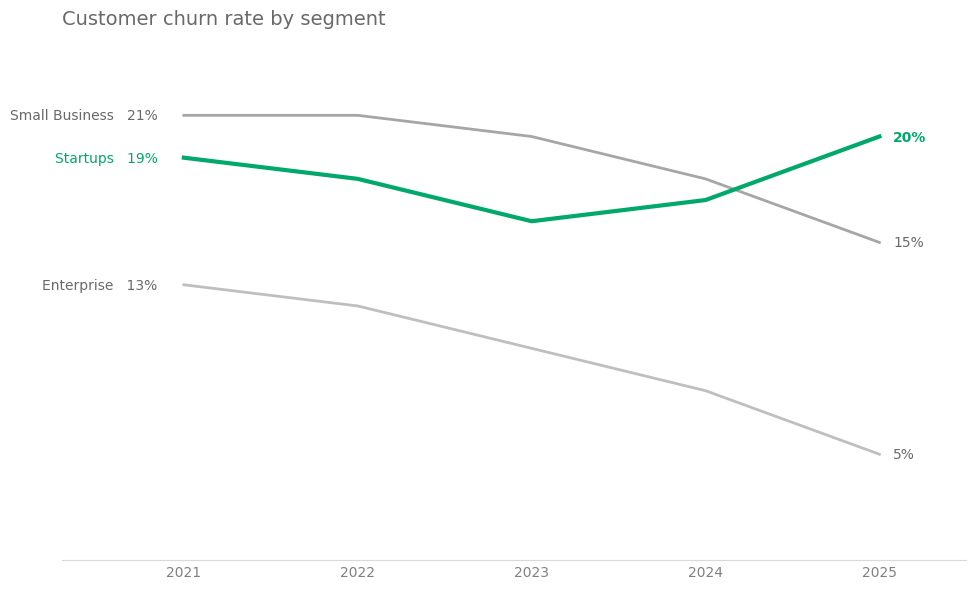

In [50]:
#Customer Churn Rate by Segment

#Years
years = [2021,2022, 2023,2024,2025]

#Churn Rates
small_business = [21,21,20,18,15]
startups = [19,18,16,17,20]
enterprise = [13,12,10,8,5]

#Figure
fig, ax=plt.subplots(figsize=(10,6))

ax.plot(years,small_business, color='#a6a6a6',linewidth=2)
ax.plot(years,startups, color='#00a86b',linewidth=3)
ax.plot(years,enterprise, color='#bfbfbf',linewidth=2)

#Labels
ax.text(2020.85, 21, 'Small Business   21%',ha='right',va ='center',fontsize=10,color='dimgray')
ax.text(2020.85, 19, 'Startups   19%',ha='right',va ='center',fontsize=10,color='#00a86b')
ax.text(2020.85, 13, 'Enterprise   13%',ha='right',va ='center',fontsize=10,color='dimgray')

ax.text(2025.08, 15, '15%',va ='center',fontsize=10,color='dimgray')
ax.text(2025.08, 20, '20%',va ='center',fontsize=10,color='#00a86b',fontweight='bold')
ax.text(2025.08, 5, '5%',va ='center',fontsize=10,color='dimgray')

#Chart Title
ax.set_title('Customer churn rate by segment',loc='left',fontsize=14,color='dimgray',pad=20)

#Format
ax.set_xlim(2020.3, 2025.5)
ax.set_ylim(0,24)

ax.set_xticks(years)
ax.set_yticks([])

#Remove Borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.spines['bottom'].set_color('#d9d9d9')
ax.tick_params(axis='x', length=0, colors='gray')
ax.grid(False)

plt.tight_layout()
plt.show()
